In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import (
    chi2_contingency,
    ttest_ind,
    mannwhitneyu,
    shapiro
)

df = sns.load_dataset("titanic")

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (891, 15)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB

Missing Values:
survived         0
pclass    

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
#Hypothesis 01 :Does gender affect survival?


#Question: Were survival rates different for male and female passengers?
#- H0 (Null Hypothesis): Gender and survival are independent.
#- H1 (Alternative Hypothesis): Gender and survival are associated.

# Create contingency table
gender_survival = pd.crosstab(
    df["sex"],
    df["survived"]
)

print(gender_survival)

# Perform Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(
    gender_survival
)

print("Chi-Square Statistic:", chi2)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0: Gender and survival are associated.")
else:
    print("Fail to reject H0: No significant association found.")

survived    0    1
sex               
female     81  233
male      468  109
Chi-Square Statistic: 260.71702016732104
P-Value: 1.1973570627755645e-58
Reject H0: Gender and survival are associated.


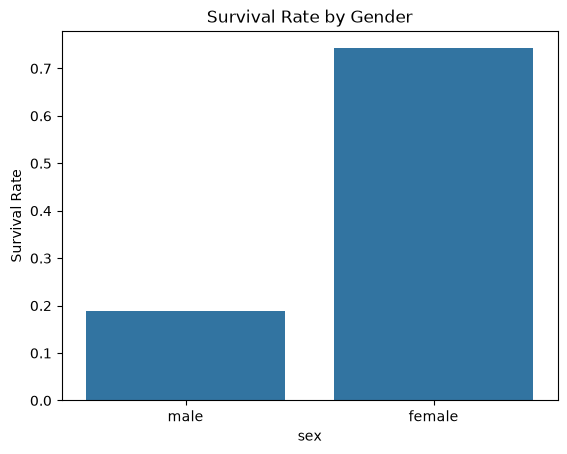

In [4]:
#Visualisation:

sns.barplot(
    data=df,
    x="sex",
    y="survived",
    errorbar=None
)

plt.title("Survival Rate by Gender")
plt.ylabel("Survival Rate")
plt.show()

In [ ]:
#Hypothesis 2: Did survivors and non-survivors have different average ages?


#H0: Both groups have the same average age.
#H1: Their average ages are different.


# Remove missing age values
survived_age = df[df["survived"] == 1]["age"].dropna()

not_survived_age = df[df["survived"] == 0]["age"].dropna()

# Perform independent t-test
t_stat, p_value = ttest_ind(
    survived_age,
    not_survived_age,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0: Average ages are significantly different.")
else:
    print("Fail to reject H0: No significant age difference found.")

T-Statistic: -2.0460301043939704
P-Value: 0.04118965162586637
Reject H0: Average ages are significantly different.


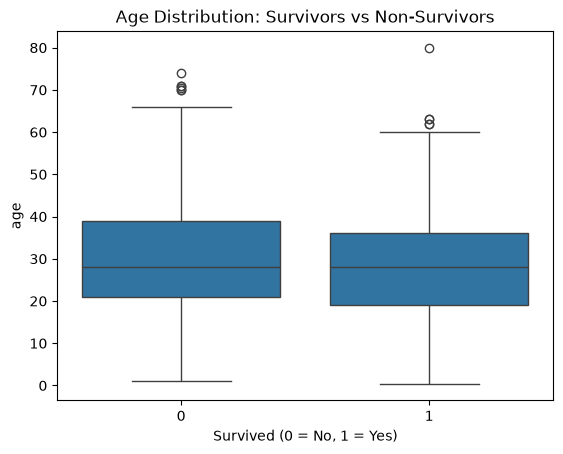

In [6]:
#Visualisation

sns.boxplot(
    data=df,
    x="survived",
    y="age"
)

plt.title("Age Distribution: Survivors vs Non-Survivors")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

In [7]:
#Hypothesis 3: Did passenger class relate to survival?

#H0: Passenger class and survival are independent.
#H1: Passenger class and survival are associated.

class_survival = pd.crosstab(
    df["class"],
    df["survived"]
)

chi2, p_value, dof, expected = chi2_contingency(
    class_survival
)

print("Contingency Table:")
print(class_survival)

print("\nChi-Square Statistic:", chi2)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0: Passenger class and survival are associated.")
else:
    print("Fail to reject H0: No significant association found.")

Contingency Table:
survived    0    1
class             
First      80  136
Second     97   87
Third     372  119

Chi-Square Statistic: 102.88898875696056
P-Value: 4.549251711298793e-23
Reject H0: Passenger class and survival are associated.


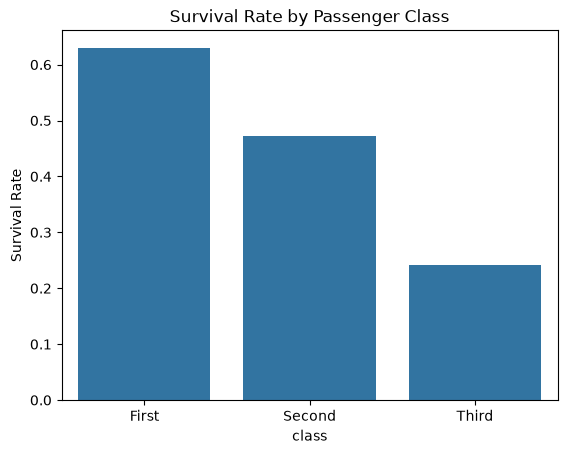

In [8]:
#Visualisation

sns.barplot(
    data=df,
    x="class",
    y="survived",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

In [ ]:
#final results table

results = pd.DataFrame({
    "Hypothesis": [
        "Gender vs Survival",
        "Age vs Survival",
        "Passenger Class vs Survival"
    ],
    "Test": [
        "Chi-Square",
        "Independent T-Test",
        "Chi-Square"
    ],
    "P-Value": [
        chi2_contingency(gender_survival)[1],
        ttest_ind(
            survived_age,
            not_survived_age,
            equal_var=False
        ).pvalue,
        chi2_contingency(class_survival)[1]
    ]
})

results["Conclusion"] = np.where(
    results["P-Value"] < 0.05,
    "Statistically Significant",
    "Not Statistically Significant"
)

display(results)

,Hypothesis,Test,P-Value,Conclusion
0,Gender vs Survival,Chi-Square,1.197357e-58,Statistically Significant
1,Age vs Survival,Independent T-Test,4.118965e-02,Statistically Significant
2,Passenger Class vs Survival,Chi-Square,4.549252e-23,Statistically Significant
